# Day 4 (Task 1): Dataset Exploration and Preparation

Plan for this notebook:
1. Look at the raw data and find the problems
2. Clean it
3. Summary statistics, probability and correlation
4. Split into train, validation and test sets

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("houses_raw.csv")
df.head()

,area_marla,bedrooms,bathrooms,age_years,location_zone,price_million_pkr
0,12.5,5,5.0,11.0,Central,23.58
1,5.5,1,1.0,NaN,Outskirts,5.05
2,10.5,3,2.0,15.0,Central,16.35
3,18.5,4,3.0,23.0,Suburban,23.27
4,11.5,3,2.0,22.0,Suburban,15.20


## 1. First look

In [2]:
print("Shape:", df.shape)
print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values per column:")
print(df.isna().sum())
print("\nZone labels as they appear:")
print(df["location_zone"].value_counts())

Shape: (305, 6)

Duplicate rows: 5

Missing values per column:
area_marla            0
bedrooms              0
bathrooms            10
age_years            15
location_zone         0
price_million_pkr     0
dtype: int64

Zone labels as they appear:
location_zone
Suburban      124
Outskirts      90
Central        72
central        11
 Suburban       8
Name: count, dtype: int64


In [3]:
df.describe().round(2)

,area_marla,bedrooms,bathrooms,age_years,price_million_pkr
count,305.00,305.00,295.00,290.00,305.00
mean,12.56,2.90,2.40,14.46,15.28
std,11.72,1.31,1.28,9.06,5.93
min,3.00,1.00,1.00,0.00,3.32
25%,7.50,2.00,1.00,7.00,10.94
50%,11.50,3.00,2.00,14.00,15.27
75%,15.50,4.00,3.00,22.00,19.31
max,120.00,6.00,5.00,30.00,28.55


Problems found:
- `bathrooms` and `age_years` have missing values
- 5 duplicate rows
- `location_zone` has the same zone written in different ways (`central`, ` Suburban `)
- `area_marla` has a maximum of 120, which is not a believable house size

## 2. Cleaning

In [4]:
clean = df.copy()
rows_start = len(clean)

# 1. fix inconsistent text
clean["location_zone"] = clean["location_zone"].str.strip().str.title()

# 2. remove duplicates
clean = clean.drop_duplicates()
print("After dropping duplicates:", len(clean), "rows")

# 3. find outliers in area using the 1.5 x IQR rule
q1, q3 = clean["area_marla"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Allowed area range: {low:.1f} to {high:.1f} marla")
print("Outlier areas:", clean.loc[~clean["area_marla"].between(low, high), "area_marla"].tolist())

After dropping duplicates: 300 rows
Allowed area range: -4.7 to 27.8 marla
Outlier areas: [120.0, 120.0, 120.0]


In [5]:
clean = clean[clean["area_marla"].between(low, high)]
print("After removing outliers:", len(clean), "rows")

# 4. fill missing numbers with the median (safe against outliers)
for col in ["bathrooms", "age_years"]:
    clean[col] = clean[col].fillna(clean[col].median())
clean["bathrooms"] = clean["bathrooms"].astype(int)
clean["age_years"] = clean["age_years"].astype(int)

clean = clean.reset_index(drop=True)
print("\nMissing values left:", clean.isna().sum().sum())
print(f"Rows: {rows_start} -> {len(clean)}")
clean["location_zone"].value_counts()

After removing outliers: 297 rows

Missing values left: 0
Rows: 305 -> 297


location_zone
Suburban     128
Outskirts     88
Central       81
Name: count, dtype: int64

## 3. Statistics, probability and correlation

In [6]:
clean.describe().round(2)

,area_marla,bedrooms,bathrooms,age_years,price_million_pkr
count,297.00,297.00,297.00,297.00,297.00
mean,11.50,2.90,2.39,14.40,15.31
std,4.76,1.32,1.26,8.81,5.94
min,3.00,1.00,1.00,0.00,3.32
25%,7.50,2.00,1.00,7.00,10.94
50%,11.50,3.00,2.00,14.00,15.36
75%,15.50,4.00,3.00,22.00,19.31
max,20.00,6.00,5.00,30.00,28.55


In [7]:
# Probability: how likely is each zone, and how likely is an expensive house in each zone?
expensive = clean["price_million_pkr"] > 15
print("P(zone):")
print(clean["location_zone"].value_counts(normalize=True).round(3))
print("\nP(price > 15 million | zone):")
print(expensive.groupby(clean["location_zone"]).mean().round(3))
print("\nP(price > 15 million) overall:", round(expensive.mean(), 3))

P(zone):
location_zone
Suburban     0.431
Outskirts    0.296
Central      0.273
Name: proportion, dtype: float64

P(price > 15 million | zone):
location_zone
Central      0.580
Outskirts    0.443
Suburban     0.547
Name: price_million_pkr, dtype: float64

P(price > 15 million) overall: 0.525


area_marla    0.918
bedrooms      0.845
bathrooms     0.773
age_years     0.031
Name: price_million_pkr, dtype: float64


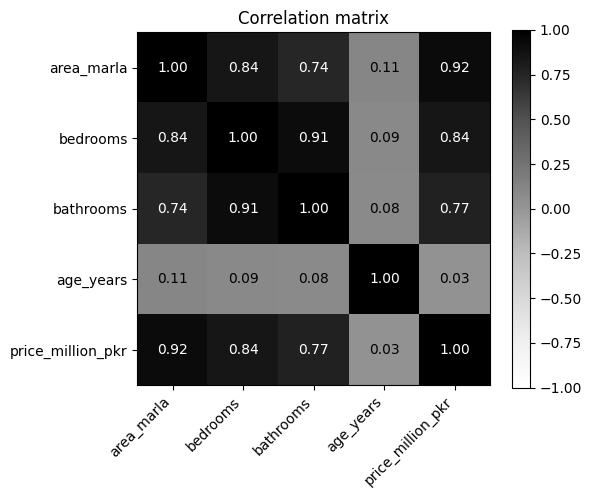

In [8]:
num = clean.select_dtypes("number")
corr = num.corr()
print(corr["price_million_pkr"].drop("price_million_pkr").sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if abs(v) > 0.5 else "black")
fig.colorbar(im)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

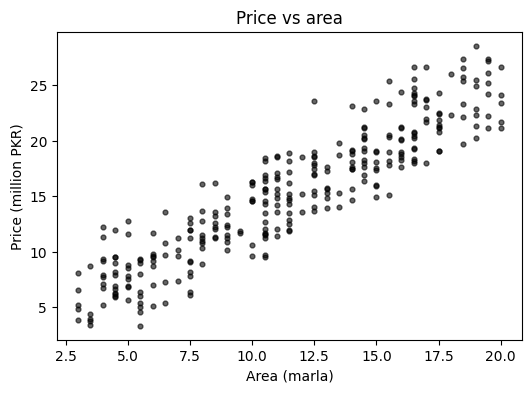

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(clean["area_marla"], clean["price_million_pkr"], s=12, color="black", alpha=0.6)
ax.set_xlabel("Area (marla)")
ax.set_ylabel("Price (million PKR)")
ax.set_title("Price vs area")
plt.show()

Area has the strongest link with price, and bedrooms and bathrooms move with area as well (bigger
houses have more rooms). Age shows almost no linear relationship with price (about 0.03) in this data. Remember that correlation is not causation.

## 4. Train / validation / test split (70 / 15 / 15)
First take 70% for training, then cut the remaining 30% in half. `random_state=42` keeps the split
repeatable.

In [10]:
train, temp = train_test_split(clean, test_size=0.30, random_state=42)
val, test = train_test_split(temp, test_size=0.50, random_state=42)

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s}: {len(part):4d} rows ({len(part) / len(clean):.0%})")

train     :  207 rows (70%)
validation:   45 rows (15%)
test      :   45 rows (15%)


In [11]:
# Save the cleaned data and the three splits for the next days
clean.to_csv("houses_clean.csv", index=False)
train.to_csv("train.csv", index=False)
val.to_csv("validation.csv", index=False)
test.to_csv("test.csv", index=False)
print("Saved houses_clean.csv, train.csv, validation.csv, test.csv")

Saved houses_clean.csv, train.csv, validation.csv, test.csv
